# Does Discretization Help a Rule-Based Classifier? (WEKA Study Reproduced in Python)

Our original WEKA study tested whether binning continuous attributes improves the **DecisionTable** classifier on the Pima Indians Diabetes data. This notebook rebuilds the experiment in Python, from scratch:

- A **DecisionTable** classifier (Kohavi, 1995): pick a subset of attributes, then classify each case by the majority class of training rows that match it on those attributes, falling back to the overall majority when nothing matches
- Three discretizers: **equal-width** (unsupervised, 10 bins as in WEKA), **MDL supervised** (Fayyad and Irani, 1993) and **PKI** (proportional k-interval, √n equal-frequency bins)
- 10-fold cross-validation, repeated 5 times

It also checks a methodological point: applying a supervised filter to the whole dataset before cross-validation lets label information leak into the test folds.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

sns.set_theme(style="whitegrid")
data, _ = arff.loadarff("data/diabetes.arff")
df = pd.DataFrame(data)
df["class"] = df["class"].str.decode("utf-8")
X, y = df.drop(columns="class"), (df["class"] == "tested_positive").astype(int).values
print(X.shape, "| positive rate:", y.mean().round(3))
X.describe().T.round(1)

(768, 8) | positive rate: 0.349


,count,mean,std,min,25%,50%,75%,max
preg,768.0,3.8,3.4,0.0,1.0,3.0,6.0,17.0
plas,768.0,120.9,32.0,0.0,99.0,117.0,140.2,199.0
pres,768.0,69.1,19.4,0.0,62.0,72.0,80.0,122.0
skin,768.0,20.5,16.0,0.0,0.0,23.0,32.0,99.0
insu,768.0,79.8,115.2,0.0,0.0,30.5,127.2,846.0
mass,768.0,32.0,7.9,0.0,27.3,32.0,36.6,67.1
pedi,768.0,0.5,0.3,0.1,0.2,0.4,0.6,2.4
age,768.0,33.2,11.8,21.0,24.0,29.0,41.0,81.0


## 1. The classifier

In [2]:
class DecisionTable(BaseEstimator, ClassifierMixin):
    """Kohavi's DecisionTable with greedy forward attribute selection.

    The table maps each combination of selected attribute values to the majority class
    of matching training rows. Unmatched cases get the overall majority class.
    Attribute subsets are scored by leave-one-out accuracy of the table, which can be
    computed exactly from the cell counts.
    """
    def __init__(self, max_attrs=5):
        self.max_attrs = max_attrs

    @staticmethod
    def _keys(X, cols):
        return [tuple(r) for r in np.asarray(X)[:, cols]]

    def _loo_acc(self, X, y, cols):
        keys = self._keys(X, cols)
        cells = {}
        for k, t in zip(keys, y):
            cells.setdefault(k, [0, 0])[t] += 1
        overall = np.bincount(y, minlength=2)
        correct = 0
        for k, t in zip(keys, y):
            c = cells[k].copy(); c[t] -= 1                 # leave this row out
            if sum(c) == 0:
                o = overall.copy(); o[t] -= 1; pred = int(o[1] > o[0])
            else:
                pred = int(c[1] > c[0])
            correct += pred == t
        return correct / len(y)

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        self.majority_ = int(np.bincount(y).argmax())
        chosen, best = [], 0.0
        while len(chosen) < self.max_attrs:
            scores = {j: self._loo_acc(X, y, chosen + [j]) for j in range(X.shape[1]) if j not in chosen}
            j, s = max(scores.items(), key=lambda kv: kv[1])
            if s <= best: break
            chosen.append(j); best = s
        self.attrs_ = chosen
        table = {}
        for k, t in zip(self._keys(X, chosen), y):
            table.setdefault(k, [0, 0])[t] += 1
        self.table_ = {k: int(c[1] > c[0]) for k, c in table.items()}
        self.classes_ = np.array([0, 1])
        return self

    def predict(self, X):
        if not self.attrs_:
            return np.full(len(X), self.majority_)
        return np.array([self.table_.get(k, self.majority_) for k in self._keys(X, self.attrs_)])

## 2. The discretizers

In [3]:
class EqualWidth(BaseEstimator, TransformerMixin):
    """Unsupervised equal-width binning (WEKA Discretize, 10 bins by default)."""
    def __init__(self, bins=10):
        self.bins = bins
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.edges_ = [np.linspace(c.min(), c.max(), self.bins + 1)[1:-1] for c in X.T]
        return self
    def transform(self, X):
        X = np.asarray(X, float)
        return np.column_stack([np.digitize(c, e) for c, e in zip(X.T, self.edges_)])

class PKI(EqualWidth):
    """Proportional k-interval: sqrt(n) equal-frequency bins."""
    def fit(self, X, y=None):
        X = np.asarray(X, float); k = int(np.sqrt(len(X)))
        self.edges_ = [np.unique(np.quantile(c, np.linspace(0, 1, k + 1)[1:-1])) for c in X.T]
        return self

def _entropy(y):
    p = np.bincount(y, minlength=2) / len(y)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

class MDL(EqualWidth):
    """Supervised discretization by Fayyad and Irani's entropy/MDL criterion."""
    def _cuts(self, x, y):
        order = np.argsort(x); x, y = x[order], y[order]
        n, ent = len(y), _entropy(y)
        best = None
        for i in np.where(np.diff(x) > 0)[0]:
            l, r = y[:i + 1], y[i + 1:]
            e = (len(l) * _entropy(l) + len(r) * _entropy(r)) / n
            if best is None or e < best[0]:
                best = (e, i, l, r)
        if best is None:
            return []
        e, i, l, r = best
        gain = ent - e
        k, k1, k2 = len(np.unique(y)), len(np.unique(l)), len(np.unique(r))
        delta = np.log2(3 ** k - 2) - (k * ent - k1 * _entropy(l) - k2 * _entropy(r))
        if gain <= (np.log2(n - 1) + delta) / n:
            return []
        cut = (x[i] + x[i + 1]) / 2
        return self._cuts(x[:i + 1], y[:i + 1]) + [cut] + self._cuts(x[i + 1:], y[i + 1:])
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y)
        self.edges_ = [np.array(sorted(self._cuts(c, y))) for c in X.T]
        return self

mdl = MDL().fit(X, y)
pd.Series({col: len(e) + 1 for col, e in zip(X.columns, mdl.edges_)}, name="MDL intervals (full data)").to_frame().T

,preg,plas,pres,skin,insu,mass,pedi,age
MDL intervals (full data),2,4,1,1,3,2,2,2


MDL keeps only the cut points that carry information about the class. Several attributes collapse into a single interval, which removes them from the table's attribute search entirely.

## 3. Experiment: discretizer fitted inside each fold

In [4]:
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=1)
setups = {
    "Original (no discretization)": DecisionTable(),
    "Unsupervised equal-width (10 bins)": make_pipeline(EqualWidth(), DecisionTable()),
    "Supervised MDL": make_pipeline(MDL(), DecisionTable()),
    "PKIDiscretize (sqrt(n) bins)": make_pipeline(PKI(), DecisionTable()),
}
rows = []
for name, model in setups.items():
    s = cross_val_score(model, X, y, cv=cv)
    rows.append({"setup": name, "accuracy": s.mean(), "std": s.std()})
res = pd.DataFrame(rows).set_index("setup")
res["WEKA (original study)"] = [0.7122, 0.7239, 0.7617, 0.7395]
res.round(4)

,accuracy,std,WEKA (original study)
setup,,,
Original (no discretization),0.6588,0.0381,0.7122
Unsupervised equal-width (10 bins),0.7292,0.0408,0.7239
Supervised MDL,0.7456,0.0487,0.7617
PKIDiscretize (sqrt(n) bins),0.7234,0.0450,0.7395


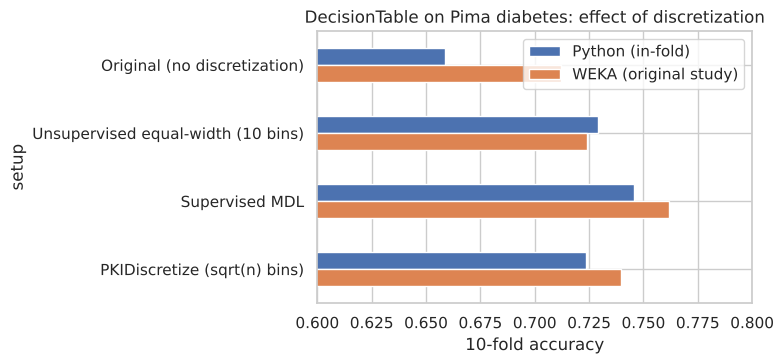

In [5]:
ax = res[["accuracy", "WEKA (original study)"]].rename(columns={"accuracy": "Python (in-fold)"}).plot.barh(figsize=(8, 3.8))
ax.set_xlim(0.6, 0.8); ax.set_xlabel("10-fold accuracy"); ax.invert_yaxis()
ax.set_title("DecisionTable on Pima diabetes: effect of discretization")
plt.tight_layout(); plt.savefig("images/accuracy_comparison.png", dpi=120); plt.show()

## 4. Leakage check: supervised filter applied before cross-validation

In the WEKA Explorer it is easy to apply a supervised filter in the Preprocess tab and then cross-validate in the Classify tab. That chooses cut points using every row's label, including rows that later serve as test data.

In [6]:
X_leaky = MDL().fit(X, y).transform(X)
leak = cross_val_score(DecisionTable(), X_leaky, y, cv=cv).mean()
proper = res.loc["Supervised MDL", "accuracy"]
print(f"MDL fitted on all data, then CV: {leak:.4f}")
print(f"MDL fitted inside each fold:      {proper:.4f}")
print(f"optimistic bias:                  {100 * (leak - proper):+.2f} points")

MDL fitted on all data, then CV: 0.7781
MDL fitted inside each fold:      0.7456
optimistic bias:                  +3.25 points


In [7]:
final = DecisionTable().fit(MDL().fit(X, y).transform(X), y)
print("attributes chosen by the table:", [X.columns[j] for j in final.attrs_])

attributes chosen by the table: ['plas', 'mass', 'age', 'pedi']


## Conclusions

- **Discretization helps DecisionTable.** On raw continuous values almost every case is unique, so the table rarely finds a match and falls back to the majority class. Binning creates repeated value combinations the table can learn from.
- **Supervised MDL gives the best accuracy**, in line with the WEKA result, because its cut points are chosen to separate the classes.
- **Supervised filters must be fitted inside the cross-validation loop.** Fitting them on all the data first leaks label information and inflates accuracy. The leakage check above measures the size of that bias on this dataset.
- The exact numbers differ from WEKA because this DecisionTable uses greedy forward selection rather than WEKA's best-first search, and the folds differ. The pattern across methods is the same.